In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
# comment="#" skips the header lines that the archive puts at the top of the file
df = pd.read_csv("exoplanet_data.csv", comment="#")

In [3]:
print(df.shape)
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")

(597, 92)
Rows: 597, Columns: 92


In [4]:
# all column titles
for col in df.columns:
    print(col)

pl_name
hostname
default_flag
sy_snum
sy_pnum
discoverymethod
disc_year
disc_facility
soltype
pl_controv_flag
pl_refname
pl_orbper
pl_orbpererr1
pl_orbpererr2
pl_orbperlim
pl_orbsmax
pl_orbsmaxerr1
pl_orbsmaxerr2
pl_orbsmaxlim
pl_rade
pl_radeerr1
pl_radeerr2
pl_radelim
pl_radj
pl_radjerr1
pl_radjerr2
pl_radjlim
pl_bmasse
pl_bmasseerr1
pl_bmasseerr2
pl_bmasselim
pl_bmassj
pl_bmassjerr1
pl_bmassjerr2
pl_bmassjlim
pl_bmassprov
pl_orbeccen
pl_orbeccenerr1
pl_orbeccenerr2
pl_orbeccenlim
pl_insol
pl_insolerr1
pl_insolerr2
pl_insollim
pl_eqt
pl_eqterr1
pl_eqterr2
pl_eqtlim
ttv_flag
st_refname
st_spectype
st_teff
st_tefferr1
st_tefferr2
st_tefflim
st_rad
st_raderr1
st_raderr2
st_radlim
st_mass
st_masserr1
st_masserr2
st_masslim
st_met
st_meterr1
st_meterr2
st_metlim
st_metratio
st_logg
st_loggerr1
st_loggerr2
st_logglim
sy_refname
rastr
ra
decstr
dec
sy_dist
sy_disterr1
sy_disterr2
sy_vmag
sy_vmagerr1
sy_vmagerr2
sy_kmag
sy_kmagerr1
sy_kmagerr2
sy_gaiamag
sy_gaiamagerr1
sy_gaiamagerr2
rowupdat

Shape: 597 rows and 92 columns. Each row is one set of parameters for a planet discovered in 2019.

Five column titles I had no idea about:
1. pl_orbperlim: no idea at first. It is some kind of "limit flag" attached to the orbital period.
2. pl_controv_flag: some flag about the planet being "controversial".
3. soltype: "solution type" of what?
4. st_metratio: some ratio about the star's metallicity.
5. sy_gaiamag: a magnitude measured by the Gaia telescope.

In [5]:
# Table Label: Planet Name
# Database Column Name: pl_name
# Description: the standard name given to the planet (host star name plus a letter, like "b").
# In my own words: the planet's name, like a label so we can tell planets apart.

# Table Label: Host Name
# Database Column Name: hostname
# Description: the name of the star the planet orbits.
# In my own words: which star the planet goes around.

# Table Label: Discovery Method
# Database Column Name: discoverymethod
# Description: the technique that was used to first detect the planet.
# In my own words: how astronomers found the planet (transit, radial velocity, imaging, ...).

# Table Label: Spectral Type
# Database Column Name: st_spectype
# Description: the classification of the host star's spectrum (letter for temperature, number, then luminosity class).
# In my own words: what kind of star it is. O, B, A, F, G, K, M go from hot to cool, and the Sun is G2 V.

# Table Label: Equilibrium Temperature [K]
# Database Column Name: pl_eqt
# Description: the temperature a planet would have if it only absorbed and re-emitted its star's light.
# In my own words: roughly how hot the planet is, in Kelvin, based on its distance from its star.

# Table Label: Planet Mass or Mass*sin(i) [Jupiter Mass]
# Database Column Name: pl_bmassj
# Description: the planet's mass in Jupiters (or only a lower limit, Mass*sin(i), when the tilt of the orbit is unknown).
# In my own words: how heavy the planet is compared to Jupiter.

In [6]:
columns = ["pl_name", "hostname", "discoverymethod", "st_spectype", "pl_eqt", "pl_bmassj"]
small = df[columns]
small.shape

(597, 6)

In [7]:
# drop any row that has a NaN in any of these columns
small = small.dropna()

In [8]:
print(small.shape)
print(f"Rows: {small.shape[0]}, Columns: {small.shape[1]}")

(75, 6)
Rows: 75, Columns: 6


In [9]:
print(small.head())
print(small.tail())

     pl_name hostname  discoverymethod st_spectype  pl_eqt  pl_bmassj
2   DMPP-1 b   DMPP-1  Radial Velocity        F8 V   877.0   0.076362
5   DMPP-1 c   DMPP-1  Radial Velocity        F8 V  1239.0   0.030205
7   DMPP-1 d   DMPP-1  Radial Velocity        F8 V  1632.0   0.010540
8   DMPP-1 e   DMPP-1  Radial Velocity        F8 V  1314.0   0.012994
10  DMPP-2 b   DMPP-2  Radial Velocity        F5 V  1000.0   0.437000
         pl_name   hostname  discoverymethod st_spectype  pl_eqt  pl_bmassj
572   WASP-185 b   WASP-185          Transit        G0 V  1160.0      0.980
576   WASP-190 b   WASP-190          Transit     F6 IV-V  1500.0      1.000
581   WASP-192 b   WASP-192          Transit        G0 V  1620.0      2.300
586       XO-7 b       XO-7          Transit        G0 V  1743.0      0.709
593  eps Ind A b  eps Ind A  Radial Velocity        K5 V   275.0      6.310


In [10]:
for col in small.columns:
    print(col)

pl_name
hostname
discoverymethod
st_spectype
pl_eqt
pl_bmassj


Shape of the smaller dataset: 75 rows and 6 columns. Dropping the NaN rows removed most of the data (from 597 down to 75), because some rows dont have either an equilibrium temperature or spectral type.

In [11]:
counts = small["discoverymethod"].value_counts()
print(counts)

discoverymethod
Transit            60
Radial Velocity    13
Imaging             2
Name: count, dtype: int64


Discovery methods: Transit (60), Radial Velocity (13) and Imaging (2).
Most: Transit, with 60 planets.
Fewest: Imaging, with only 2 planets.

In my own words:
Transit: a telescope watches a star's brightness. If a planet passes in front of the star, the star dims a tiny bit and then comes back. Repeating dips mean there is a planet.
Radial Velocity: a planet's gravity makes the star wobble back and forth. The wobble shifts the star's light slightly toward blue and red, and we measure that shift.
Imaging: taking an actual picture of the planet, by blocking out the star's light so the faint planet next to it can be seen.

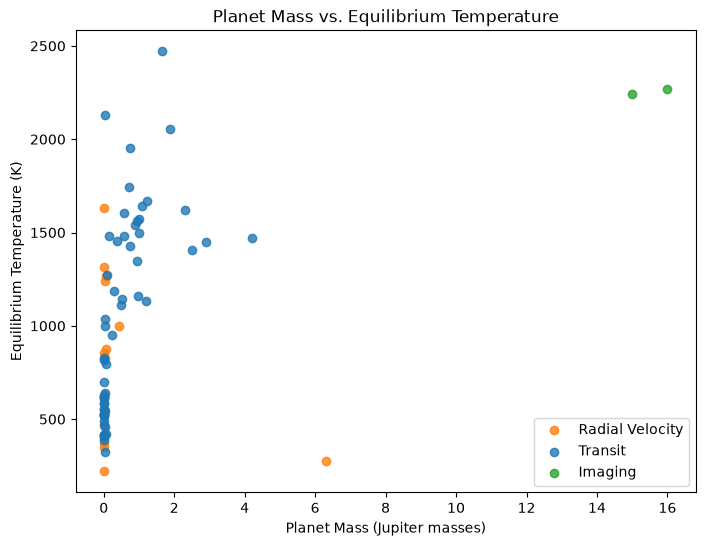

In [12]:
methods = small["discoverymethod"].unique()
colors = {"Transit": "tab:blue", "Radial Velocity": "tab:orange", "Imaging": "tab:green"}

fig, ax = plt.subplots(figsize=(8, 6))
for m in methods:
    sub = small[small["discoverymethod"] == m]
    ax.scatter(sub["pl_bmassj"], sub["pl_eqt"], color=colors[m], label=m, alpha=0.8)
ax.set_title("Planet Mass vs. Equilibrium Temperature")
ax.set_xlabel("Planet Mass (Jupiter masses)")
ax.set_ylabel("Equilibrium Temperature (K)")
ax.legend()
plt.show()

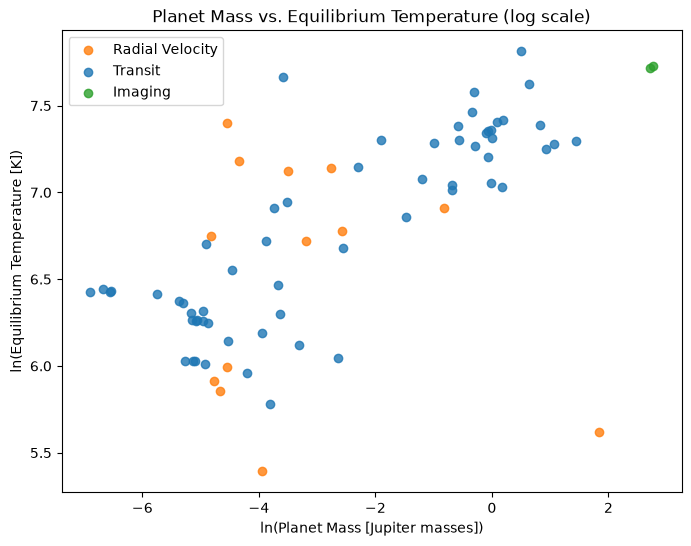

In [13]:
# same plot, with np.log() on both axes
fig, ax = plt.subplots(figsize=(8, 6))
for m in methods:
    sub = small[small["discoverymethod"] == m]
    ax.scatter(np.log(sub["pl_bmassj"]), np.log(sub["pl_eqt"]), color=colors[m], label=m, alpha=0.8)
ax.set_title("Planet Mass vs. Equilibrium Temperature (log scale)")
ax.set_xlabel("ln(Planet Mass [Jupiter masses])")
ax.set_ylabel("ln(Equilibrium Temperature [K])")
ax.legend()
plt.show()

Imaging planets: massive or small? Massive. The two imaged planets are the ones that are on the far right of the plot, because to take a picture of a planet it has to be big and bright enough to stand out next to its star.

In [14]:
# coldest planet with a mass larger than 5 Jupiter masses
heavy = small[small["pl_bmassj"] > 5]
coldest = heavy.loc[heavy["pl_eqt"].idxmin()]
coldest_index = heavy["pl_eqt"].idxmin()
print(small.loc[[coldest_index]])

         pl_name   hostname  discoverymethod st_spectype  pl_eqt  pl_bmassj
593  eps Ind A b  eps Ind A  Radial Velocity        K5 V   275.0       6.31


In [15]:
print("Name:", coldest["pl_name"])
print("Index:", coldest_index)
print("Equilibrium temperature (K):", coldest["pl_eqt"])
print("Mass (Jupiter masses):", coldest["pl_bmassj"])
print("Star spectral type:", coldest["st_spectype"])

Name: eps Ind A b
Index: 593
Equilibrium temperature (K): 275.0
Mass (Jupiter masses): 6.31
Star spectral type: K5 V


The coldest planet over 5 Jupiter masses is eps Ind A b
Name: eps Ind A b
- Index: 593
- Equilibrium temperature: 275 K
- Mass: 6.31 Jupiter masses
- Star: spectral type K5 V, so a K-type main sequence star (a "V" means a dwarf star, like the Sun).

Is it a sun-like star? Sort of, the Sun is a G2 V star. K5 V is a bit cooler, smaller and more orange than the Sun, but it is a main-sequence star thats about the same age as the Sun, so it is a lot closer to the Sun than the M-type stars of the imaged planets.

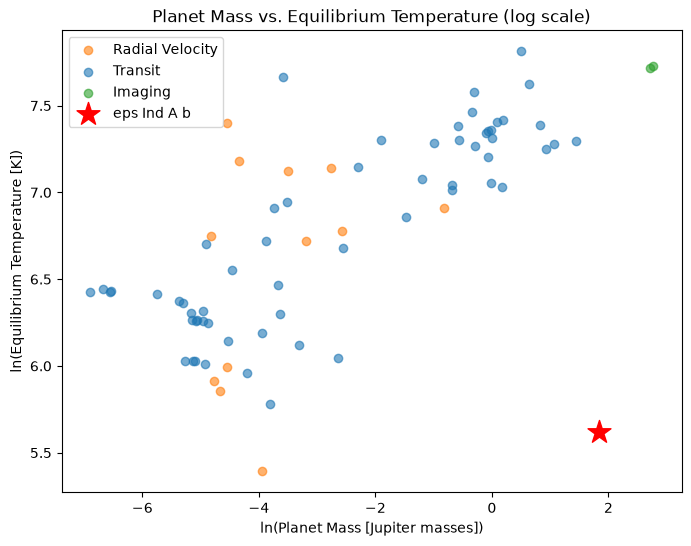

In [16]:
fig, ax = plt.subplots(figsize=(8, 6))
for m in methods:
    sub = small[small["discoverymethod"] == m]
    ax.scatter(np.log(sub["pl_bmassj"]), np.log(sub["pl_eqt"]), color=colors[m], label=m, alpha=0.6)
ax.scatter(np.log(coldest["pl_bmassj"]), np.log(coldest["pl_eqt"]),
           color="red", marker="*", s=300, label=coldest["pl_name"], zorder=5)
ax.set_title("Planet Mass vs. Equilibrium Temperature (log scale)")
ax.set_xlabel("ln(Planet Mass [Jupiter masses])")
ax.set_ylabel("ln(Equilibrium Temperature [K])")
ax.legend()
plt.show()

Title of the paper: “A temperate super-Jupiter imaged with JWST in the mid-infrared” (Matthews et al., Nature, 2024).

Summary of the abstract (my words): Most of the ~25 planets we’ve actually taken pictures of are young and hot. This paper used the James Webb Space Telescope to image a giant planet around Eps Ind A, which is a K5 V star pretty close to the Sun in age. People already thought there was a planet there because of how the star moves, and this planet fits that. But it doesn’t match what was claimed about it before. It’s cold, only about 275 K, and really bright at 10.65 and 15.50 micrometers. It wasn’t seen at 3.5 to 5 micrometers, so something in its atmosphere must be blocking that light. The authors guess it could have a lot of heavy elements or more carbon compared to oxygen. The temperature also fits models of how planets cool down, which hadn’t been tested this cold before. They think it’s the only giant planet there, so they just call it “b”.

Does the answer match my exoplanet? Yes, it’s eps Ind A b, orbiting the K5 V star Eps Ind A, at 275 K.

What is special about it? It’s cold (about 275 K) but still found by direct imaging, and it’s around an older star like the Sun. Most imaged planets are young and hot, so this one is unusual. It also lets scientists check their cooling models at low temperatures. And the star is only about 3.6 parsecs away, so it’s really close to us.

Do the mass and temperature match the paper? Yes, both match. The archive lists 6.31 Jupiter masses and the paper reports 6.31 (+0.60/−0.56) Jupiter masses. The temperature is about 275 K in both.